<a href="https://colab.research.google.com/github/hcarpenter30/IS4487_my_portfolio/blob/main/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset directly
try:
    df = pd.read_csv('/content/cleaned_airbnb_data_6.csv')
    print("Successfully loaded cleaned_airbnb_data_6.csv!")
except FileNotFoundError:
    print("Error: 'cleaned_airbnb_data_6.csv' not found. Please upload it to the /content/ folder.")

# Display the first few rows of the dataset
if 'df' in locals():
    print(df.head())

Successfully loaded cleaned_airbnb_data_6.csv!
     id                        listing_url       scrape_id last_scraped  \
0   360   https://www.airbnb.com/rooms/360  20260630053644   2026-06-30   
1   364   https://www.airbnb.com/rooms/364  20260630053644   2026-07-02   
2   592   https://www.airbnb.com/rooms/592  20260630053644   2026-06-30   
3   686   https://www.airbnb.com/rooms/686  20260630053644   2026-06-30   
4  1940  https://www.airbnb.com/rooms/1940  20260630053644   2026-06-30   

            source                                               name  \
0      city scrape  Denver’s Peaceful Oasis for Travel Nurses & No...   
1  previous scrape                Lodo / RiNo LOFT  via airport train   
2      city scrape                                            private   
3      city scrape   Alexandra's Queen Bed Room Long-term Rental Only   
4      city scrape         Baker Studio Pet-friendly, Walkable, Patio   

                                         description  \
0  Enjo

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

Original Price Skewness: 63.89
Log-Transformed Price Skewness: 0.32


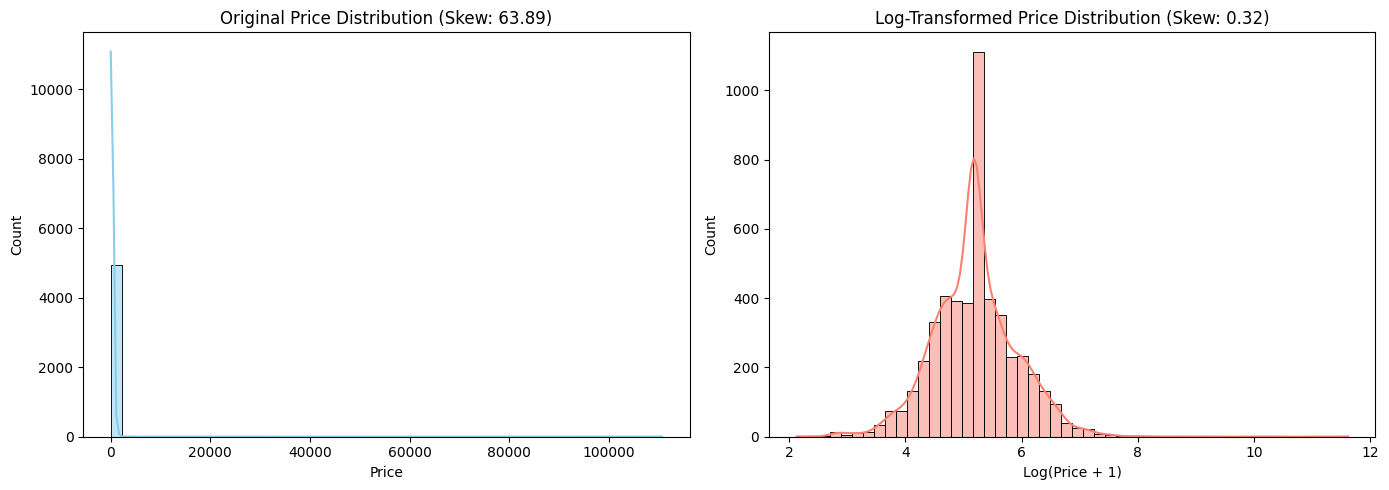

In [ ]:
# Clean and prepare the 'price' column if it is currently stored as a string with currency formatting
if df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)

# Calculate original skewness
original_skew = df['price'].skew()
print(f"Original Price Skewness: {original_skew:.2f}")

# Apply a log1p transformation to safely handle zero or positive values
df['price_log'] = np.log1p(df['price'])
transformed_skew = df['price_log'].skew()
print(f"Log-Transformed Price Skewness: {transformed_skew:.2f}")

# Plot the distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Original Distribution
sns.histplot(df['price'].dropna(), bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f'Original Price Distribution (Skew: {original_skew:.2f})')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Count')

# Plot 2: Log-Transformed Distribution
sns.histplot(df['price_log'].dropna(), bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title(f'Log-Transformed Price Distribution (Skew: {transformed_skew:.2f})')
axes[1].set_xlabel('Log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column in the dataset.

2. The transformation I chose was a log transformaton because it made the data easier to read, easier to visualize, and better for models to interpret.

3. The transformed version removed currency characters if they were present and cleaned up the dataset. It makes it more usable for data visualizations, as well as for the skewness of the variables.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Ensure there are no missing values in our target columns for scaling
df['minimum_nights'] = df['minimum_nights'].fillna(df['minimum_nights'].median())
df['number_of_reviews'] = df['number_of_reviews'].fillna(0)

# Initialize scale tools
min_max_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

# Apply Min-Max scaling to 'minimum_nights'
df['minimum_nights_minmax'] = min_max_scaler.fit_transform(df[['minimum_nights']])

# Apply Z-score Normalization to 'number_of_reviews'
df['number_of_reviews_zscore'] = standard_scaler.fit_transform(df[['number_of_reviews']])

# Display the descriptive stats to verify transformations
print("--- Summary of original vs transformed columns ---")
display(df[['minimum_nights', 'minimum_nights_minmax', 'number_of_reviews', 'number_of_reviews_zscore']].describe())

--- Summary of original vs transformed columns ---


,minimum_nights,minimum_nights_minmax,number_of_reviews,number_of_reviews_zscore
count,4939.000000,4939.000000,4939.000000,4.939000e+03
mean,17.397044,0.032860,71.805224,-2.301819e-17
std,24.461451,0.049021,125.811201,1.000101e+00
min,1.000000,0.000000,0.000000,-5.707957e-01
25%,1.000000,0.000000,3.000000,-5.469480e-01
50%,7.000000,0.012024,21.000000,-4.038620e-01
75%,29.000000,0.056112,85.000000,1.048882e-01
max,500.000000,1.000000,1798.000000,1.372191e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response:
1. The columns I scaled were Minimum_nights, and number_of_reviews. I used minmax for the first column and zscores for the second.

2. When you need certain values to be constrained or need to standardize the values in a column whether that be the mean or standard deviation, which by using z scores, you can do both.

3. The analysts might benefit from this transformation because it will make it easier to read and understand, not to mention being able to visualize it in a different way and compare different columns and variables.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [ ]:
# Group 'availability_365' into 3 bins: Low, Medium, High
# Since availability has many 0s and 365s, we can use pd.cut with defined boundaries
# Bins: 0-120 days (Low), 121-240 days (Medium), 241-365 days (High)
bins = [-1, 120, 240, 365]
labels = ['Low', 'Medium', 'High']

# Create the new column
df['availability_category'] = pd.cut(df['availability_365'], bins=bins, labels=labels)

# Display the value distribution of the new column
print("Value counts for availability_category:")
print(df['availability_category'].value_counts(dropna=False))

Value counts for availability_category:
availability_category
High      2397
Low       1425
Medium    1117
Name: count, dtype: int64


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. The column I grouped into bins was available_365. I used 3 categories, low, medium, and high, to represent the days of availability for the listing over the year.

2. Because its easier to read and understand. than large numbers. having three bins makes it less noisy too, and easy to understand the availablity if it is labeled as "low" as compared to 100 days.

3. This would help the customers or analysts trying to better understand the dataset and the different property listings within.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [ ]:
# 1. Create a ratio/interaction column: Price per person accommodated
# We'll use the 'accommodates' column, ensuring we handle zero division gracefully
df['price_per_accommodate'] = df['price'] / df['accommodates'].replace(0, np.nan)

# 2. Create a conditional flag column: Stays longer than 30 days
df['is_long_term_stay'] = (df['minimum_nights'] > 30).astype(int)

# Preview the new columns to verify their addition
print("--- Preview of the new columns ---")
display(df[['price', 'accommodates', 'price_per_accommodate', 'minimum_nights', 'is_long_term_stay']].head())

--- Preview of the new columns ---


,price,accommodates,price_per_accommodate,minimum_nights,is_long_term_stay
0,106.35,2,53.175000,29.0,0
1,32.35,3,10.783333,185.0,1
2,80.00,2,40.000000,2.0,0
3,44.27,1,44.270000,30.0,0
4,191.72,2,95.860000,1.0,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response:
1. I created price_per_accommodate to look at pricing efficiency per guest, and is_long_term_stay to identify long-term rental listings.

2. I believe hosts would use them as well as analysts too because it adds another layer to the data set, allows people to compare to more columns and variables, and is overall a great addition for hosts, analysts, but also managers.

3. They help someone make a better decision because they can weigh the decison with new criteria now being price per person as well as the listing being available for long term stay or not. Overall it makes the decision making process easier.

## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [ ]:
# Inspect the unique categories in the 'room_type' column
print("Unique room types:", df['room_type'].unique())

# One-hot encode the nominal 'room_type' column using pandas
room_type_dummies = pd.get_dummies(df['room_type'], prefix='room_type', dtype=int)

# Concatenate the new one-hot encoded columns back to our DataFrame
df = pd.concat([df, room_type_dummies], axis=1)

# Display a preview of the newly created encoded columns
print("\n--- Preview of the encoded room type columns ---")
display(df[['room_type'] + list(room_type_dummies.columns)].head())

Unique room types: ['Entire home/apt' 'Private room' 'Shared room' 'Hotel room']

--- Preview of the encoded room type columns ---


,room_type,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,Entire home/apt,1,0,0,0
1,Entire home/apt,1,0,0,0
2,Private room,0,0,1,0
3,Private room,0,0,1,0
4,Entire home/apt,1,0,0,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response:
1. The column I encoded was room_type because its easier to have numerical values than text string when it comes to making decions and creating algorithms.
2. For this column, I used one-hot encoding.
3. It could make the data more consistent and simplified, if you can encode certain parts of a dataset to numbers as opposed to text, especially when making important business decisions.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [ ]:
# Export the transformed dataset to a CSV file for Assignment 11
output_filename = '/content/cleaned_airbnb_data_7.csv'

df.to_csv(output_filename, index=False)
print(f"Successfully exported the cleaned and transformed dataset to: {output_filename}")
print(f"DataFrame shape: {df.shape}")

Successfully exported the cleaned and transformed dataset to: /content/cleaned_airbnb_data_7.csv
DataFrame shape: (4939, 96)


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



1. I believe applying the log transformation to the price column was the most interesting and important step. It was cool to see how a heavily skewed distribution could be reshaped into a nearly perfect bell curve.

2. The custom engineered columns, specifically price_per_accommodate and the one-hot encoded room_type categories would be very valuable and useful for a host on airbnb.

3. For me, I would build an interactive map displaying average price_per_accommodate alongside a categorical filter for availability_category, so that travelers can find highly available listings across different neighborhoods.

4. This directly connects with learning how to properly clean and enrich raw datasets into modeled feature sets that are ready to support business intelligence tools. Especially  in the world of finance, having accurate datasets is very importabt, and this assignment taught me various ways to ensure that is the case, and that everything is easy to read and interpret.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 408430 bytes to assignment_07_data_transformation.html
